In [1]:
# !pip install torch torchvision matplotlib scikit-learn tqdm pytz
import os
import numpy as np
import torch
from torch import nn
import torch.utils.data as Data
import torchvision
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import pytz
from datetime import datetime

from Algo.get_algos import get_algorithm
from data_util.DataTransformBuilder import build_data_transform
from data_util.DataDistributer import DataPartitioner
from data_util.TinyImageNet_reader import TinyImageNet_reader
from data_util.PACS_reader import Pacs_reader
from data_util.Four_dataset_reader import four_dataset_reader
from Scenario import FL_scenario
from util.TOdevice import to_device
from Models.L2P_heuristic_model import L2P_ViT_B32, L2P_DeiT_B16, L2P_ConViT_Base
from util.saving_tools import load_model_trainable_part


In [2]:
class Args:
    gpus = "1"
    alg = "fedavg"
    dataset = "cifar10"  # ["cifar10","cifar100","PACS","tinyimagenet","fourdataset"]
    device = "cuda:1" if torch.cuda.is_available() else "cpu"
    n_clients = 80
    batch = 64
    n_sampled_clients = 10
    data_distribution = "non_iid_dirichlet"  # ["non_iid_dirichlet","manual_extreme_heterogeneity"]
    alpha = 0.5
    n_dominated_class = 1
    model_type = "L2P"
    prompt_method = "shallow"
    n_tokens = 4
    dominated_ratio = 0.99
    load_model = None

    # L2P params
    pool_size = 20
    batchwise_prompt = False
    query_model_type = "vit_cls" #deit_b16, convit_base, vit_cls
    dp_mechanism = "no_dp"  # ["no_dp","Laplace","Gaussian","AnalyticGaussian","Staircase","Prompt"]
    eps = 1.0
    
    # MIA params
    batch_size_mia = 1
    delta_min = 0.5
    delta_max = 0.05
    beta =0 

args = Args()
os.environ["CUDA_VISIBLE_DEVICES"] = args.gpus


In [3]:
norm_stats = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
resize = 256
centercrop_size = 224
preprocess = build_data_transform(norm_stats, resize, centercrop_size)

class_mask = None
if args.dataset == 'cifar10':
    trainset = torchvision.datasets.CIFAR10(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR10(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 10
elif args.dataset == 'cifar100':
    trainset = torchvision.datasets.CIFAR100(root='./Dataset', train=True, download=True, transform=preprocess)
    testset  = torchvision.datasets.CIFAR100(root='./Dataset', train=False, download=True, transform=preprocess)
    num_classes = 100
elif args.dataset == 'PACS':
    data_name = ['art_painting', 'cartoon', 'photo', 'sketch']
    trainset = [Pacs_reader('./Dataset/PACS', split=d, train=True,  transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = [Pacs_reader('./Dataset/PACS', split=d, train=False, transform=preprocess, random_seed=i) for i, d in enumerate(data_name)]
    testset  = Data.ConcatDataset(testset)
    num_classes = 28
elif args.dataset == 'tinyimagenet':
    trainset = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=True,  transform=preprocess)
    testset  = TinyImageNet_reader('./Dataset/tiny-imagenet-200/', train=False, transform=preprocess)
    num_classes = 200
elif args.dataset == 'fourdataset':
    data_name = ['mnistm', 'fashion', 'cinic10', 'mmafedb']
    trainset, class_mask = four_dataset_reader([30000]*4, train=True,  transform=preprocess)
    testset, _          = four_dataset_reader([2500]*4,  train=False, transform=preprocess)
    num_classes = 37
    print(args.dataset)
else:
    raise ValueError("Unsupported dataset")

# global testloader
if args.dataset == 'fourdataset':
    testloader = [Data.DataLoader(testset[i], batch_size=args.batch, num_workers=2, shuffle=False) for i in range(len(testset))]
else:
    testloader = Data.DataLoader(testset, batch_size=args.batch, num_workers=2, shuffle=False)

# data partitioner
if args.dataset in ['PACS', 'fourdataset']:
    data_partitioner = [DataPartitioner(trainset[i], args.n_clients // len(data_name)) for i in range(len(trainset))]
else:
    data_partitioner = DataPartitioner(trainset, args.n_clients)

# alpha→seed mapping (kept as-is)
if args.alpha == 0.1: 
    seed = 871
elif args.alpha == 0.2: 
    seed = 459
elif args.alpha == 0.3: 
    seed = 429
elif args.alpha == 0.4: 
    seed = 3760
elif args.alpha == 0.5: 
    seed = 448
else: 
    seed = 1234


/home/quannm/.local/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [4]:
if args.n_clients > args.n_sampled_clients:
    scenrio_type = 'cross_devices'
else:
    scenrio_type = 'cross_silo'

LATz = pytz.timezone("America/Los_Angeles")
timeInLA = datetime.now(LATz)

if args.data_distribution == 'non_iid_dirichlet':
    if isinstance(data_partitioner, list):
        for i, part in enumerate(data_partitioner):
            if i == 0:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)
            else:
                part.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=data_partitioner[0].seed)
    else:
        data_partitioner.dirichlet_split_noniid(alpha=args.alpha, least_samples=32, manual_seed=seed)

elif args.data_distribution == 'manual_extreme_heterogeneity':
    if isinstance(data_partitioner, list):
        for part in data_partitioner:
            part.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)
    else:
        data_partitioner.manual_allocating_noniid(args.n_dominated_class, args.dominated_ratio, 1.0)

    base = f"{args.model_type}_{args.alg}_{args.dataset}_{args.n_clients}clietns_{scenrio_type}_{args.data_distribution}_({args.instance_label})"
else:
    raise ValueError("Unsupported data distribution")



In [5]:
# build FL scenario (unchanged structure)
if args.dataset in ['PACS', 'fourdataset']:
    all_clients_weights = np.concatenate([p.get_all_client_weights() for p in data_partitioner])
    loaders = [p.get_distributed_data(batch_size=args.batch) for p in data_partitioner]
    distributed_dataloaders = [loaders[i][j] for i in range(len(loaders)) for j in range(data_partitioner[i].n_clients)]
    fl_scen = FL_scenario(all_clients_weights, args.n_clients, args.n_sampled_clients, distributed_dataloaders)
else:
    fl_scen = FL_scenario(
        data_partitioner.get_all_client_weights(),
        args.n_clients, args.n_sampled_clients,
        data_partitioner.get_distributed_data(batch_size=args.batch)
    )

# model
if args.model_type != 'L2P':
    raise ValueError("Only L2P path shown here")

server_model = to_device(
    L2P_ViT_B32(prompt_method=args.prompt_method,
                batchwise_prompt=args.batchwise_prompt,
                pool_size=args.pool_size,
                top_k=args.n_tokens,
                num_classes=num_classes,
                candidate_key=None),
    args.device
)
server_model.build_trainable_keys()

In [6]:
# pick algorithm
associate_algo = args.alg.split('_')[0] if '_' in args.alg else args.alg
algclass = get_algorithm(associate_algo)

if args.alg == 'fedavg_nonpara':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='nonparametric_aggregation',
                    nonpara_hidden=args.nonpara_hidden, class_mask=class_mask, device=args.device)
elif args.alg == 'fedavg':
    algo = algclass(server_model=server_model, scenario=fl_scen,
                    loss_fun=nn.CrossEntropyLoss(), fed_method='aggregation',
                    class_mask=class_mask, device=args.device)
else:
    raise ValueError("Unsupported algorithm")

In [7]:
if args.dataset == 'PACS' or args.dataset == 'fourdataset':
    train_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in trainset]
    test_dataloader_list = [torch.utils.data.DataLoader(dataset, batch_size=args.batch_size_mia, shuffle=False) for dataset in testset]
else:
    train_dataloader_list = [torch.utils.data.DataLoader(trainset, batch_size=args.batch_size_mia, shuffle=False)]
    test_dataloader_list = [torch.utils.data.DataLoader(testset, batch_size=args.batch_size_mia, shuffle=False)]
mia_dataloader_list = train_dataloader_list
mia_dataloader_list_test = test_dataloader_list

In [ ]:
args.load_model = '/home/quannm/code/icml_promptmia/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt'
# args.load_model = None
if args.load_model is not None:
    load_model_trainable_part(algo.server_model, args.load_model)
    print(f"Model loaded from {args.load_model}\n")
# 🔒 snapshot keys once
with torch.no_grad():
    fixed_keys = algo.server_model.pool.key.clone()
    fixed_key_norm_torch = algo.server_model.pool.l2_normalize(fixed_keys, dim=1)
    fixed_key_norm = fixed_key_norm_torch.cpu().numpy()

# pick the dataset (train or test, member or non-member)
dataset = mia_dataloader_list[0].dataset       # e.g., first dataloader (train/member)
dataset_test = mia_dataloader_list_test[0].dataset 

# choose the sample id directly
sample_id = 10   # 👈 change this index to select which x you want
x, label = dataset[sample_id]
x_test, label_test = dataset_test[sample_id]

# add batch dimension and move to device
x = x.unsqueeze(0).to(args.device).float()
x_test = x_test.unsqueeze(0).to(args.device).float()

# --- get q(x) for train sample ---
with torch.no_grad():
    feat_train = algo.server_model.get_cls_keys(x)                 # feature vector
    query_vector_train = feat_train.repeat(args.n_tokens, 1)       # repeated for consistency
    x_embed_norm = algo.client_model[0].pool.l2_normalize(feat_train, dim=1)
    query_vector_norm_train = algo.client_model[0].pool.l2_normalize(query_vector_train, dim=1)

# convert to numpy
x_vector = x_embed_norm.detach().cpu().numpy()

# --- get q(x_test) for test sample ---
with torch.no_grad():
    feat_test = algo.server_model.get_cls_keys(x_test)
    query_vector_test = feat_test.repeat(args.n_tokens, 1)
    x_test_embed_norm = algo.client_model[0].pool.l2_normalize(feat_test, dim=1)
    query_vector_norm_test = algo.client_model[0].pool.l2_normalize(query_vector_test, dim=1)

# convert to numpy
x_test_vector = x_test_embed_norm.detach().cpu().numpy()


Model loaded from /home/quannm/code/icml_promptmia/output_record/saved_model/saved_model_L2P_fedavg_cifar10_80clietns_cross_devices_modelvit_cls_non_iid_dirichlet_alpha0.5_1_round_61_acc_0.9442.pt



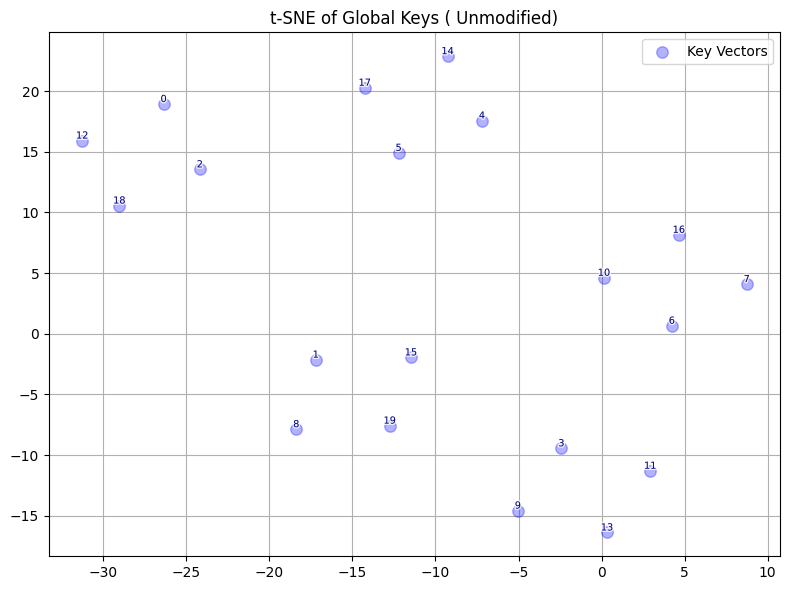

In [10]:
import matplotlib.patheffects as pe
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.linear_model import SGDOneClassSVM
from sklearn.kernel_approximation import RBFSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# combine fixed keys + single query
combined = np.concatenate([fixed_key_norm], axis=0)

# t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=10)
tsne_result = tsne.fit_transform(combined)

key_count = len(fixed_key_norm)       # N_keys
query_index = key_count               # last row is the query

plt.figure(figsize=(8, 6))
plt.scatter(tsne_result[:key_count, 0], tsne_result[:key_count, 1],
            c='blue', alpha=0.3, s=68, label='Key Vectors', zorder=5)
# plt.scatter(tsne_result[query_index, 0], tsne_result[query_index, 1],
#             c='green', edgecolors='black', s=80, marker='X',
#             label=f'Query (id={sample_id})', zorder=20)

# --- annotate key indices ---
for i in range(key_count):
    x, y = tsne_result[i]
    plt.text(x, y, str(i), fontsize=7, ha='center', va='bottom', color='navy', zorder=30,
             path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.8)])

# # --- annotate query ---
# qx, qy = tsne_result[query_index]
# plt.text(qx, qy, "Q", fontsize=9, fontweight='bold', ha='center', va='bottom',
#          color='darkgreen', zorder=32,
#          path_effects=[pe.withStroke(linewidth=2, foreground='white', alpha=0.9)])

plt.title('t-SNE of Global Keys ( Unmodified)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------
# Inputs (you already have these)
# fixed_key_norm: np.ndarray of shape (n_keys, d), L2-normalized keys
# ----------------------------

X = fixed_key_norm  # alias for readability
n_keys, dim = X.shape

# Helpful: standardize before linear / covariance models (keys are L2-normalized, but scaling still helps some methods)
scaler = StandardScaler(with_mean=False)  # with_mean=False safe if X is sparse; fine for dense too
X_scaled = scaler.fit_transform(X)

# Build detectors
detectors = {
    "IsolationForest": IsolationForest(
        n_estimators=100, max_samples='auto', contamination='auto', random_state=42
    ),
    "LocalOutlierFactor": LocalOutlierFactor(
        n_neighbors=5, contamination='auto', novelty=False
    ),
    "OneClassSVM": OneClassSVM(
        kernel="rbf", gamma="scale", nu=0.2
    ),
    # "SGDOneClassSVM (RBF approx)": make_pipeline(
    #     RBFSampler(gamma=1.0 / max(1, dim), n_components=min(2000, 4 * dim), random_state=42),
    #     SGDOneClassSVM(nu=nu, shuffle=True, random_state=42, tol=1e-3, max_iter=2000)
    # ),
    "EllipticEnvelope": EllipticEnvelope(
        contamination=0.2, support_fraction=None, random_state=42, assume_centered=False
    ),
}


# Unified fit/predict and scoring
labels_by_method = {}
scores_by_method = {}

for name, model in detectors.items():
    if name == "LocalOutlierFactor":
        # LOF outlier detection on the given set
        lof_labels = model.fit_predict(X_scaled)         # +1 inlier, -1 outlier
        # Higher score = more anomalous (negate negative_outlier_factor_)
        lof_scores = -model.negative_outlier_factor_
        labels_by_method[name] = lof_labels
        scores_by_method[name] = lof_scores
    elif name == "EllipticEnvelope":
        model.fit(X_scaled)
        # decision_function: positive = inlier, negative = outlier
        dec = model.decision_function(X_scaled)
        labels = np.where(dec >= 0, 1, -1)
        # Convert to "higher = worse" anomaly scores
        scores = -dec
        labels_by_method[name] = labels
        scores_by_method[name] = scores
    else:
        # IsolationForest, OneClassSVM, SGDOneClassSVM pipeline
        model.fit(X_scaled)
        # decision_function preferred; fallback to score_samples
        if hasattr(model, "decision_function"):
            dec = model.decision_function(X_scaled)
        else:
            dec = model.score_samples(X_scaled)
        labels = np.where(dec >= 0, 1, -1)   # convention: >=0 inlier
        scores = -dec                        # higher = more anomalous
        labels_by_method[name] = labels
        scores_by_method[name] = scores


In [11]:
# =======================
# Full script: chosen indices injection + t-SNE + Outlier Detection
# =======================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.linear_model import SGDOneClassSVM
from sklearn.kernel_approximation import RBFSampler
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import make_pipeline
import warnings
warnings.filterwarnings("ignore")
import torch
from tqdm import tqdm

def safe_div(a, b):
    return (a / b) if b != 0 else 0.0


with torch.no_grad():
    fixed_keys = algo.server_model.pool.key.clone()
    fixed_key_norm_torch = algo.server_model.pool.l2_normalize(fixed_keys, dim=1)
    fixed_key_norm = fixed_key_norm_torch.cpu().numpy()

# pick the dataset (train or test, member or non-member)
dataset = mia_dataloader_list[0].dataset       # e.g., first dataloader (train/member)
dataset_test = mia_dataloader_list_test[0].dataset 

sample_ids = list(range(len(dataset)))[:100]
# sample_ids = [10,20]  # Example list of sample IDs to iterate over
# Initialize accumulators
results = {name: {"TP": 0, "FP": 0, "FN": 0, "TN": 0} for name in detectors.keys()}
detectors = {
        "IsolationForest": IsolationForest(
            n_estimators=300, max_samples=20, contamination='auto', random_state=42
        ),
        "LocalOutlierFactor": LocalOutlierFactor(
            n_neighbors=10, contamination='auto', novelty=False
        ),
        "OneClassSVM": OneClassSVM(
            kernel="rbf", gamma="scale", nu=0.2
        ),
        # "SGDOneClassSVM (RBF approx)": make_pipeline(
        #     RBFSampler(gamma=1.0 / max(1, dim), n_components=min(2000, 4 * dim), random_state=42),
        #     SGDOneClassSVM(nu=nu, shuffle=True, random_state=42, tol=1e-3, max_iter=2000)
        # ),
        "EllipticEnvelope": EllipticEnvelope(
            contamination=0.2, support_fraction=None, random_state=42, assume_centered=False
        ),
    }

for sample_id in tqdm(sample_ids, desc="Processing samples"):
    sample_id = sample_id   # 👈 change this index to select which x you want
    x, label = dataset[sample_id]
    x_test, label_test = dataset_test[sample_id]

    # add batch dimension and move to device
    x = x.unsqueeze(0).to(args.device).float()
    x_test = x_test.unsqueeze(0).to(args.device).float()

    # --- get q(x) for train sample ---
    with torch.no_grad():
        feat_train = algo.server_model.get_cls_keys(x)                 # feature vector
        query_vector_train = feat_train.repeat(args.n_tokens, 1)       # repeated for consistency
        x_embed_norm = algo.client_model[0].pool.l2_normalize(feat_train, dim=1)
        query_vector_norm_train = algo.client_model[0].pool.l2_normalize(query_vector_train, dim=1)

    # convert to numpy
    x_vector = x_embed_norm.detach().cpu().numpy()

    # --- get q(x_test) for test sample ---
    with torch.no_grad():
        feat_test = algo.server_model.get_cls_keys(x_test)
        query_vector_test = feat_test.repeat(args.n_tokens, 1)
        x_test_embed_norm = algo.client_model[0].pool.l2_normalize(feat_test, dim=1)
        query_vector_norm_test = algo.client_model[0].pool.l2_normalize(query_vector_test, dim=1)

    # convert to numpy
    x_test_vector = x_test_embed_norm.detach().cpu().numpy()

    args.beta = 0
    k_top = 4
    # similarity shape: (batch, key_count)
    similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())  

    # pick indices of top-k (for the first query in the batch)
    topk_vals, topk_idxs = torch.topk(similarity[0], k=k_top, largest=True)
    chosen_idx = topk_idxs.cpu().numpy().tolist()
    # print("Chosen (top-k) indices:", chosen_idx)
    # chosen_idx = [16,17,18,19]
     # =========================
    # Bernoulli(0.5) injection
    # =========================
    inject = (np.random.rand() < 0.5)  # NEW: coin flip (True = inject)
    if inject:
        def generate_point_with_similarity(target_vec, similarity, benign_key):
            target_vec = target_vec.reshape(-1)
            benign_key = benign_key.reshape(-1)

            target_norm = target_vec / np.linalg.norm(target_vec)
            benign_norm = benign_key / np.linalg.norm(benign_key)

            rand_vec = np.random.rand(benign_key.shape[0])
            rand_vec = rand_vec / np.linalg.norm(rand_vec)

            beta = args.beta
            final_vec = (beta) * benign_norm + (1-beta) * rand_vec
            final_vec /= np.linalg.norm(final_vec)

            orthogonal_vec = final_vec - np.dot(final_vec, target_norm) * target_norm
            orthogonal_norm = orthogonal_vec / (np.linalg.norm(orthogonal_vec) + 1e-8)

            new_vec_norm = similarity * target_norm + np.sqrt(1 - similarity**2) * orthogonal_norm
            new_vec_norm /= np.linalg.norm(new_vec_norm)

            new_vec = new_vec_norm * np.linalg.norm(target_vec)
            return new_vec

        # --- convert inputs to numpy ---
        fixed_keys_np = fixed_keys.detach().cpu().numpy()
        fixed_key_norm_temp = fixed_key_norm.copy()
        query_vector_np = query_vector_train.detach().cpu().numpy().copy()

        # --- find similarity thresholds excluding chosen_idx ---
        similarity = torch.matmul(x_embed_norm, fixed_key_norm_torch.t())
        mask = np.ones(similarity.shape[1], dtype=bool)
        mask[chosen_idx] = False
        non_adv_similarity = similarity[:, mask] 
        max_val, max_idx = torch.max(non_adv_similarity, dim=1)
        # print(delta_min)
        delta_min = 0.02
        delta_max = delta_min + 0.05  # (same as you had)
        # print(delta_min, delta_max)
        similarity_start = torch.min(max_val + delta_min, torch.tensor(1, device=max_val.device)).cpu().item()
        similarity_end   = torch.min(max_val + delta_max, torch.tensor(1, device=max_val.device)).cpu().item()
        varied_target_similarities = np.random.uniform(similarity_start, similarity_end, args.n_tokens)

        non_chosen = np.where(mask)[0]  # 'mask' already excludes chosen_idx above
        anchor_idx = np.random.choice(non_chosen, size=len(chosen_idx), replace=False)
        # --- generate adversarial vectors for chosen_idx ---
        similar_points = []
        for sim, idx in zip(varied_target_similarities, anchor_idx):
            benign_key = fixed_keys_np[idx:idx+1]
            new_point = generate_point_with_similarity(query_vector_np[0], sim, benign_key)
            similar_points.append(new_point)

        similar_points_tensor = torch.tensor(similar_points, dtype=fixed_keys.dtype, device=fixed_keys.device)
        similar_points_tensor_norm = algo.client_model[0].pool.l2_normalize(similar_points_tensor, dim=1)

        fixed_key_norm_temp = fixed_key_norm.copy()
        for i, idx in enumerate(chosen_idx):
            fixed_key_norm_temp[idx] = similar_points_tensor_norm[i].detach().cpu().numpy()

        combined = np.concatenate([fixed_key_norm_temp], axis=0)

        injected_idx = chosen_idx
    else:
        # NEW: clean control (no injection)
        X = fixed_key_norm        # NEW: leave the pool unchanged
        injected_idx = []         # NEW: no positives this round
    # print("Injected Keys Indices:", injected_idx)
    # -----------------------------
    # Outlier detection on keys
    # -----------------------------
    X = fixed_key_norm_temp
    n_keys, dim = X.shape
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    contamination = 0.2
    nu = contamination

    labels_by_method, scores_by_method = {}, {}
    for name, model in detectors.items():
        if name == "LocalOutlierFactor":
            lab = model.fit_predict(X_scaled)
            sc  = -model.negative_outlier_factor_
        elif name == "EllipticEnvelope":
            model.fit(X_scaled)
            dec = model.decision_function(X_scaled)
            lab = np.where(dec >= 0, 1, -1)
            sc  = -dec
        else:
            model.fit(X_scaled)
            dec = model.decision_function(X_scaled) if hasattr(model, "decision_function") else model.score_samples(X_scaled)
            lab = np.where(dec >= 0, 1, -1)
            sc  = -dec
        labels_by_method[name] = lab
        scores_by_method[name] = sc

    # -----------------------------
    # -----------------------------
    # Print summaries
    # -----------------------------
    # top_k = min(15, n_keys)
    # print("\n===== Outlier Detection Summary =====")
    # for name in detectors.keys():
    #     labels = labels_by_method[name]
    #     scores = scores_by_method[name]
    #     out_idx = np.where(labels == -1)[0]
    #     print(f"\n{name}:")
    #     print(f"  Outliers flagged: {len(out_idx)} / {n_keys}")
    #     top_idx = np.argsort(scores)[::-1][:top_k]
    #     print(f"  Top {top_k} indices: {top_idx.tolist()}")
    #     print(f"  Top 5 (idx, score): {[(int(i), float(scores[i])) for i in top_idx[:5]]}")
    #     caught = sorted(set(out_idx).intersection(injected_idx))
    #     print(f"  Injected keys caught: {len(caught)} — {caught}")


    n_keys = X.shape[0]

    # Ground-truth labels: 1 = injected/outlier, 0 = benign
    y_true = np.zeros(n_keys, dtype=int)
    y_true[np.array(injected_idx, dtype=int)] = 1

    # print("\n=== Outlier Detection Metrics (single sample) ===")
    # print(f"Injected outlier indices (ground truth): {sorted(injected_idx)}\n")

    for name in detectors.keys():
        y_pred = (labels_by_method[name] == -1).astype(int)  # 1 = predicted outlier
        sc = scores_by_method[name]

        TP = int(np.sum((y_pred == 1) & (y_true == 1)))
        FP = int(np.sum((y_pred == 1) & (y_true == 0)))
        FN = int(np.sum((y_pred == 0) & (y_true == 1)))
        TN = int(np.sum((y_pred == 0) & (y_true == 0)))

        results[name]["TP"] += TP
        results[name]["FP"] += FP
        results[name]["FN"] += FN
        results[name]["TN"] += TN

for name, cm in results.items():
    TP, FP, FN, TN = cm["TP"], cm["FP"], cm["FN"], cm["TN"]

    precision = safe_div(TP, TP + FP)
    recall    = safe_div(TP, TP + FN)
    f1        = safe_div(2 * precision * recall, precision + recall)

    # New metrics
    TPR = safe_div(TP, TP + FN)   # same as recall
    FPR = safe_div(FP, FP + TN)

    print(f"\n=== Cumulative Results over {len(sample_ids)} samples ===")
    print(f"{name}: TP={TP}, FP={FP}, FN={FN}, TN={TN}")
    print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")
    print(f"TPR: {TPR:.4f}, FPR: {FPR:.4f}")

Processing samples:   0%|          | 0/100 [00:00<?, ?it/s]

Processing samples:  58%|█████▊    | 58/100 [15:13:06<11:01:12, 944.59s/it] 


KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import re
from statistics import mean, stdev

def parse_defense_table(path):
    rows = []
    pattern = re.compile(r'^(?:\\multirow\{.*?\}\{.*?\}\{(?P<dataset>.*?)\}|&)?\s*&\s*(?P<model>[^&]+)\s*&\s*(?P<method>[^&]+)\s*&\s*(?P<prec>[\d.]+)\s*&\s*(?P<rec>[\d.]+)\s*&\s*(?P<f1>[\d.]+)\s*\\\\')
    current_dataset = None

    for line in Path(path).read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('%'):
            continue
        if line.startswith('\\') and not line.startswith('\\multirow'):
            continue

        m = pattern.match(line)
        if not m:
            continue

        dataset = m.group('dataset')
        if dataset:
            current_dataset = dataset
        rows.append({
            'dataset': current_dataset,
            'model': m.group('model').strip(),
            'method': m.group('method').strip(),
            'precision': float(m.group('prec')),
            'recall': float(m.group('rec')),
            'f1': float(m.group('f1')),
        })

    return rows

def aggregate(rows):
    stats = {}
    for row in rows:
        method = row['method']
        stats.setdefault(method, {'precision': [], 'recall': [], 'f1': []})
        stats[method]['precision'].append(row['precision'])
        stats[method]['recall'].append(row['recall'])
        stats[method]['f1'].append(row['f1'])

    summary = {}
    for method, values in stats.items():
        summary[method] = {
            'precision_mean': mean(values['precision']),
            'precision_std': stdev(values['precision']),
            'recall_mean': mean(values['recall']),
            'recall_std': stdev(values['recall']),
            'f1_mean': mean(values['f1']),
            'f1_std': stdev(values['f1']),
            'count': len(values['precision']),
        }
    return summary

if __name__ == '__main__':
    path = Path('defense.txt')
    rows = parse_defense_table(path)
    summary = aggregate(rows)

    for method, stats in summary.items():
        print(f"{method}:")
        print(f"  precision = {stats['precision_mean']:.2f} ± {stats['precision_std']:.2f}")
        print(f"  recall    = {stats['recall_mean']:.2f} ± {stats['recall_std']:.2f}")
        print(f"  f1        = {stats['f1_mean']:.2f} ± {stats['f1_std']:.2f}")
        print(f"  count     = {stats['count']}")

IsolationForest:
  precision = 0.2672 ± 0.0700
  recall    = 1.0000 ± 0.0000
  f1        = 0.4172 ± 0.0888
  count     = 12
LocalOutlierFactor:
  precision = 0.0000 ± 0.0000
  recall    = 0.0000 ± 0.0000
  f1        = 0.0000 ± 0.0000
  count     = 12
OneClassSVM:
  precision = 0.2038 ± 0.0588
  recall    = 0.4994 ± 0.0362
  f1        = 0.2851 ± 0.0577
  count     = 12
EllipticEnvelope:
  precision = 0.0024 ± 0.0034
  recall    = 0.0052 ± 0.0075
  f1        = 0.0033 ± 0.0046
  count     = 12
